# Chapter 8: Tree-Based Algorithms and Ensemble Methods

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup

## Learning Objectives

After completing this chapter, we will be able to:

1. Understand decision trees for classification.
2. Apply random forests and bagging.
3. Understand gradient boosting.
4. Tune hyperparameters for tree-based models and ensembles.
5. Compare the performance of different ensemble methods.
6. Evaluate classification models using appropriate metrics.

## Table of Contents

1. Introduction to Decision Trees
2. Random Forests and Bagging
3. Gradient Boosting Machines
4. Hyperparameter Tuning for Trees and Ensembles
5. Comparing Ensemble Methods
6. Practical Exercises with Tree-Based Models
7. Summary

## Technical Requirements

This chapter uses Python and scikit-learn to build and evaluate tree-based machine learning models.

The main libraries are:

- NumPy for numerical operations.
- pandas for organizing datasets and results.
- Matplotlib and Seaborn for visualization.
- scikit-learn for data preparation, model training, hyperparameter tuning, and evaluation.

The examples use datasets available in scikit-learn, so separate dataset downloads are not required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Introduction to Decision Trees

A decision tree is a supervised machine learning algorithm used for classification and regression.

It makes predictions by splitting the dataset into smaller groups based on feature values. Each split creates a decision rule, and the process continues until a stopping condition is reached.

### Main Components

- **Root node:** The first node containing the entire training dataset.
- **Decision node:** A node that splits observations according to a feature condition.
- **Branch:** A path connecting nodes.
- **Leaf node:** A terminal node that produces a prediction.

### Important Hyperparameters

- `max_depth`: Maximum depth of the tree.
- `min_samples_split`: Minimum number of samples required to split a node.
- `min_samples_leaf`: Minimum number of samples required at a leaf.
- `criterion`: The function used to measure split quality.

A tree that is too deep may memorize the training data and overfit. Limiting its depth can help control model complexity.

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset shape:", X.shape)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Classes:", data.target_names)

Dataset shape: (569, 30)
Training samples: 455
Testing samples: 114
Classes: ['malignant' 'benign']


In [3]:
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print(
    "Decision Tree Accuracy:",
    round(accuracy_score(y_test, y_pred_tree), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=data.target_names
    )
)

Decision Tree Accuracy: 0.9386

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



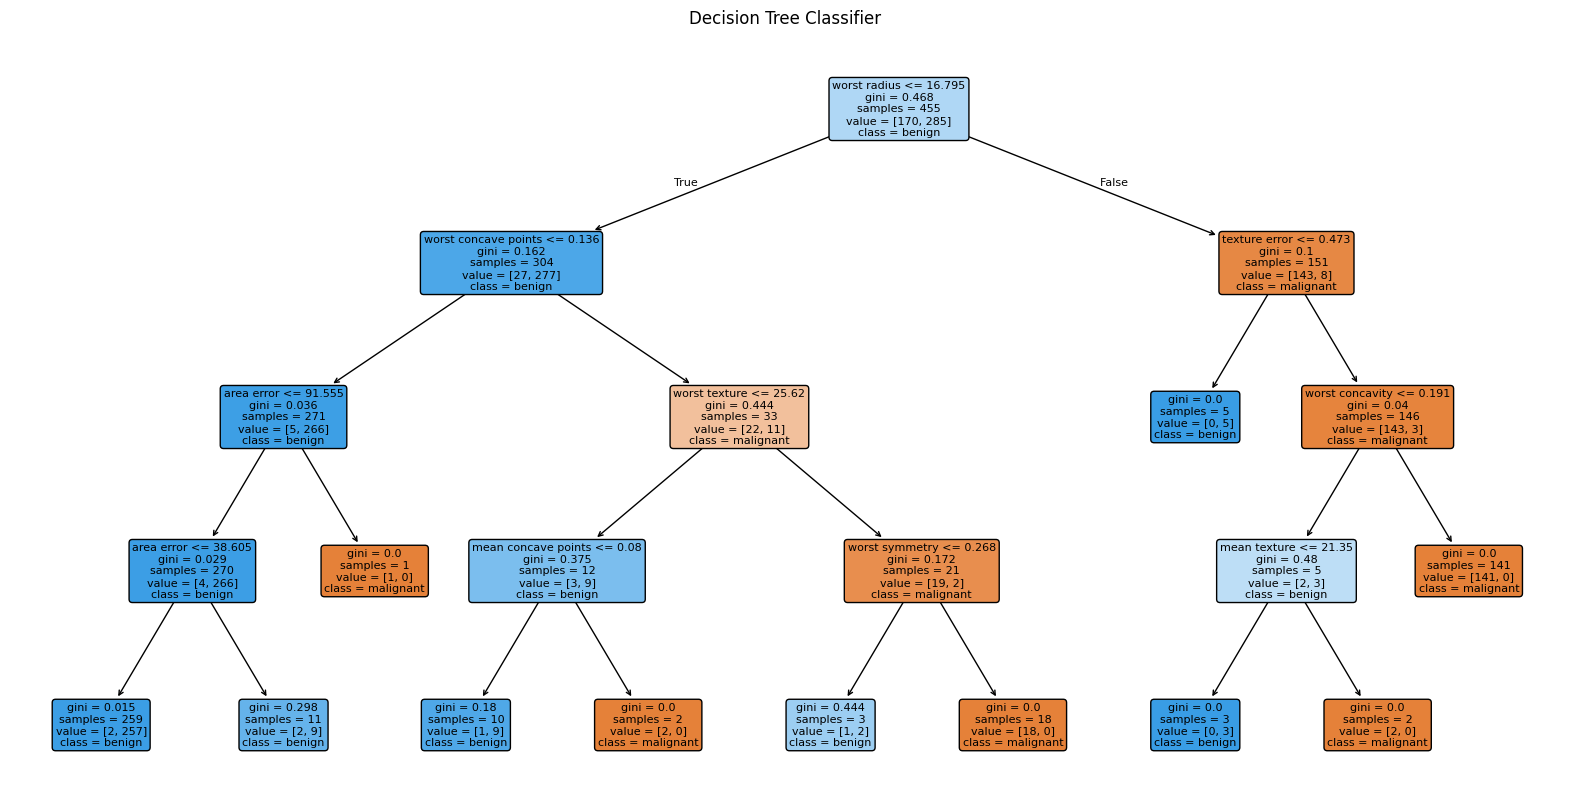

In [4]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()

### How It Works

The decision tree learns a sequence of feature-based rules from the training data.

During prediction, each observation follows the branches whose conditions match its feature values until it reaches a leaf node.

The visualization shows the selected features, split conditions, sample counts, and predicted classes at different nodes.

Limiting `max_depth` can make the tree easier to understand and may reduce overfitting. However, a shallow tree can also underfit if it is too simple to represent the data.

## 3. Gradient Boosting Machines

Gradient boosting is an ensemble technique that builds models sequentially.

Instead of training every tree independently, each new tree is fitted to help correct errors made by the current ensemble.

Important hyperparameters include:

- `n_estimators`: Number of boosting stages.
- `learning_rate`: Controls the contribution of each new tree.
- `max_depth`: Controls the complexity of individual trees.
- `subsample`: Determines the fraction of training samples used for each boosting stage.

A smaller learning rate may require more estimators. Excessively complex models or too many boosting stages can lead to overfitting.

In [5]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print(
    "Gradient Boosting Accuracy:",
    round(accuracy_score(y_test, y_pred_gb), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=data.target_names
    )
)

Gradient Boosting Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [6]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
gb_results = []

for rate in learning_rates:
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=rate,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_accuracy = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    gb_results.append({
        "Learning Rate": rate,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

gb_results_df = pd.DataFrame(gb_results)
display(gb_results_df)

,Learning Rate,Training Accuracy,Testing Accuracy
0,0.01,0.986813,0.921053
1,0.05,1.000000,0.947368
2,0.10,1.000000,0.956140
3,0.20,1.000000,0.956140


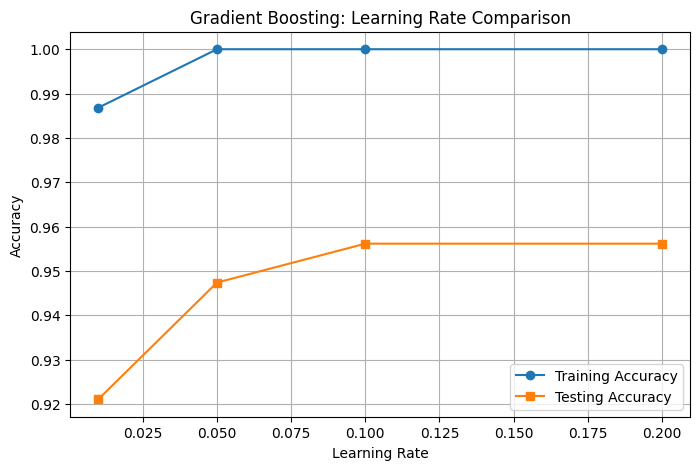

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    gb_results_df["Learning Rate"],
    gb_results_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    gb_results_df["Learning Rate"],
    gb_results_df["Testing Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Gradient Boosting: Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

### How It Works

Gradient boosting adds trees one stage at a time. Each new tree contributes to improving the ensemble's predictions.

The learning rate controls how strongly each new tree contributes. A lower learning rate can make learning more gradual, while a higher rate can make the model adapt more quickly.

The table and graph compare training and testing accuracy for several learning rates.

A large difference between training and testing performance can be a sign of overfitting. The best learning rate should be selected using validation or cross-validation, rather than choosing the highest training accuracy.

## 4. Hyperparameter Tuning for Trees and Ensembles

Hyperparameter tuning is the process of finding model settings that produce good predictive performance.

For tree-based models and ensembles, important parameters include:

- `max_depth`: Maximum depth of each tree.
- `min_samples_leaf`: Minimum number of samples allowed in a leaf.
- `n_estimators`: Number of trees or boosting stages.
- `max_features`: Number of features considered at each split.
- `learning_rate`: Contribution of each boosting stage.

GridSearchCV evaluates combinations of parameter values using cross-validation.

The testing set should remain separate during tuning so that the final evaluation provides a more reliable estimate of generalization performance.

In [8]:
rf_pipeline_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}

Best Cross-Validation Accuracy:
0.9604


In [9]:
best_rf = grid_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_test)

print(
    "Testing Accuracy:",
    round(accuracy_score(y_test, y_pred_best_rf), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best_rf,
        target_names=data.target_names
    )
)

Testing Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### How It Works

GridSearchCV tests different combinations of random forest hyperparameters using five-fold cross-validation.

The `best_params_` attribute returns the selected settings, while `best_score_` reports the best mean cross-validation score.

The tuned model is then evaluated on the separate testing set.

Cross-validation performance and testing performance may differ because they are calculated using different data. Hyperparameter tuning does not guarantee that the model will outperform every alternative.

## 5. Comparing Ensemble Methods

Different ensemble methods combine models in different ways.

- **Bagging:** Trains multiple models independently on bootstrap samples and combines their predictions.
- **Random Forest:** Uses bagging with additional randomness in feature selection.
- **Extra Trees:** Adds further randomness to the selection of split thresholds.
- **Gradient Boosting:** Builds models sequentially to improve the ensemble's predictions.

The best approach depends on the dataset, computational resources, and evaluation criteria.

A fair comparison uses the same training and testing split and evaluates every model with the same metrics.

### How It Works

GridSearchCV tests different combinations of random forest hyperparameters using five-fold cross-validation.

The `best_params_` attribute returns the selected settings, while `best_score_` reports the best mean cross-validation score.

The tuned model is then evaluated on the separate testing set.

Cross-validation performance and testing performance may differ because they are calculated using different data. Hyperparameter tuning does not guarantee that the model will outperform every alternative.

,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,0.986813,0.938596
1,Bagging,1.000000,0.938596
2,Random Forest,1.000000,0.956140
3,Extra Trees,1.000000,0.956140
4,Gradient Boosting,1.000000,0.956140


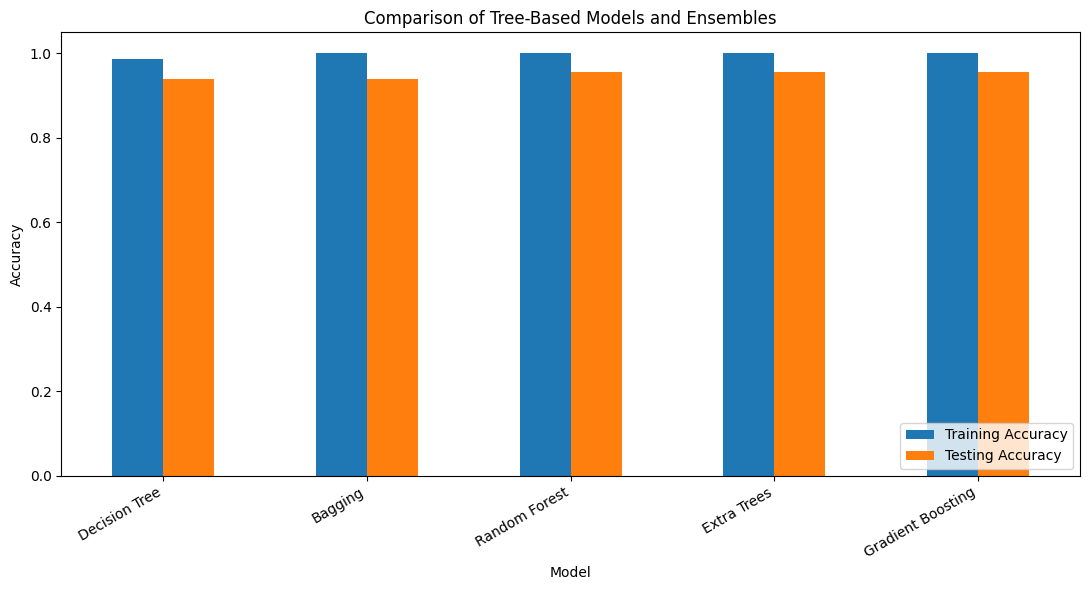

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    BaggingClassifier,
    GradientBoostingClassifier
)

# 1. Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=42
    ),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# 4. Train models and collect results
comparison_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Testing Accuracy": accuracy_score(y_test, test_pred)
    })

# 5. Create comparison DataFrame
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

# 6. Plot comparison
comparison_plot = comparison_df.set_index("Model")[
    ["Training Accuracy", "Testing Accuracy"]
]

comparison_plot.plot(kind="bar", figsize=(11, 6))

plt.ylabel("Accuracy")
plt.title("Comparison of Tree-Based Models and Ensembles")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

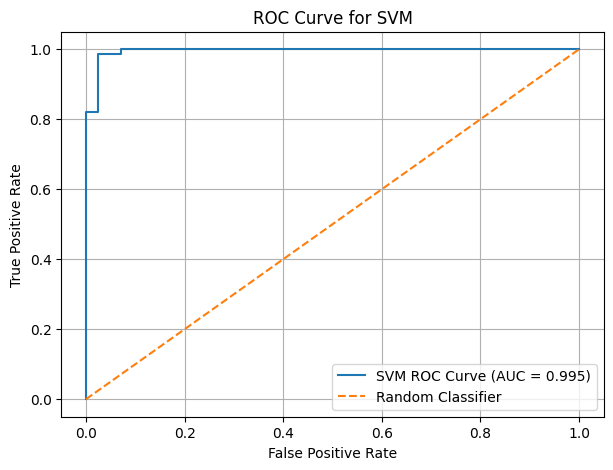

ROC AUC: 0.995


In [18]:
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc

# Create and train the SVM model
evaluation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0))
])

evaluation_model.fit(X_train, y_train)

# Get decision scores
y_scores = evaluation_model.decision_function(X_test)

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"SVM ROC Curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for SVM")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("ROC AUC:", round(roc_auc, 4))

In [19]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

comparison_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Testing Accuracy": accuracy_score(y_test, test_pred)
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Testing Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Training Accuracy,Testing Accuracy
0,Random Forest,1.000000,0.956140
1,Gradient Boosting,1.000000,0.956140
2,Extra Trees,1.000000,0.956140
3,Decision Tree,0.986813,0.938596
4,Bagging,1.000000,0.938596


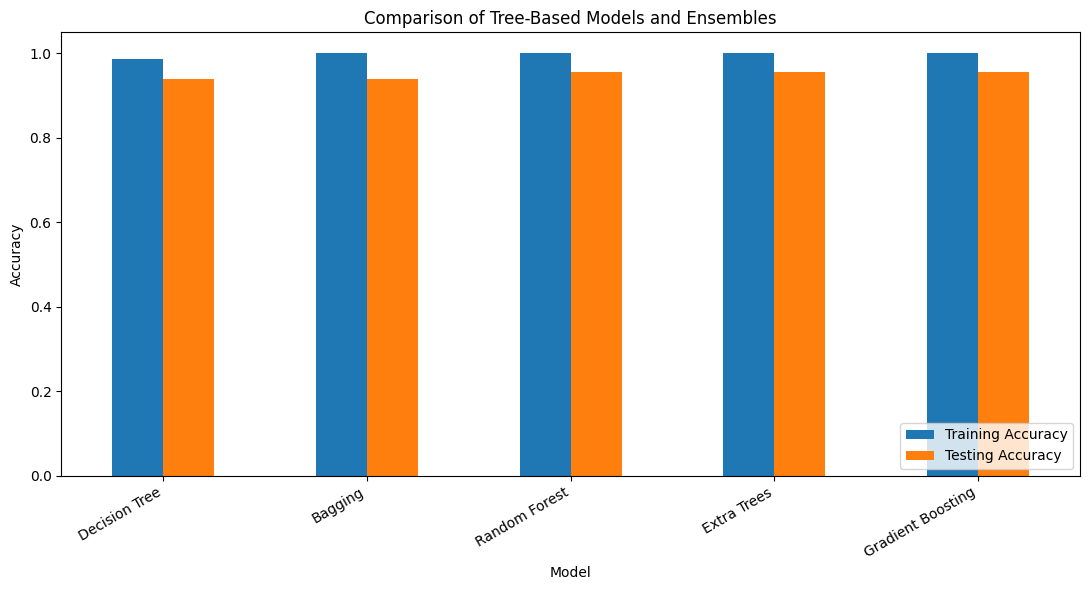

In [20]:
comparison_plot = comparison_df.set_index("Model")[
    ["Training Accuracy", "Testing Accuracy"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel("Accuracy")
plt.title("Comparison of Tree-Based Models and Ensembles")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### How It Works

The comparison table evaluates several tree-based methods using the same data split.

Training accuracy indicates how well a model fits the training data, while testing accuracy measures performance on held-out observations. A large gap between them may indicate overfitting.

The feature-importance chart shows which features contribute most to the random forest's impurity-based importance calculation.

Feature importance should not automatically be interpreted as causation. Correlated features can also influence how importance is distributed.

## 6. Practical Exercises with Tree-Based Models

### Exercise 1: Building and Evaluating a Decision Tree Classifier

Train a decision tree using the Breast Cancer dataset. Experiment with different values of `max_depth` and compare the testing accuracy.

### Exercise 2: Hyperparameter Tuning with Random Forests

Use GridSearchCV to identify a suitable combination of random forest parameters. Compare the best cross-validation score with the final testing accuracy.

### Exercise 3: Comparing Gradient Boosting and Random Forest

Train gradient boosting and random forest models using the same data split. Compare accuracy and classification reports.

These exercises are adapted practice tasks based on the chapter topics, not verbatim reproductions of the book's exercise text.

In [21]:
depth_results = []

for depth in [1, 2, 3, 4, 5, 8, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": accuracy_score(
            y_train,
            model.predict(X_train)
        ),
        "Testing Accuracy": accuracy_score(
            y_test,
            model.predict(X_test)
        )
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.923077,0.921053
1,2,0.958242,0.894737
2,3,0.975824,0.938596
3,4,0.986813,0.938596
4,5,0.993407,0.921053
5,8,1.000000,0.912281
6,None,1.000000,0.912281


In [22]:
exercise_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

exercise_grid.fit(X_train, y_train)

print("Best parameters:", exercise_grid.best_params_)
print("Best CV accuracy:", round(exercise_grid.best_score_, 4))

exercise_pred = exercise_grid.predict(X_test)

print(
    "Testing accuracy:",
    round(accuracy_score(y_test, exercise_pred), 4)
)

Best parameters: {'max_depth': None, 'n_estimators': 200}
Best CV accuracy: 0.9604
Testing accuracy: 0.9561


In [23]:
rf_exercise = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

gb_exercise = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

rf_exercise.fit(X_train, y_train)
gb_exercise.fit(X_train, y_train)

rf_pred_exercise = rf_exercise.predict(X_test)
gb_pred_exercise = gb_exercise.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred_exercise), 4))

print("Gradient Boosting Accuracy:",
      round(accuracy_score(y_test, gb_pred_exercise), 4))

print("\nRandom Forest Classification Report")
print(
    classification_report(
        y_test,
        rf_pred_exercise,
        target_names=data.target_names
    )
)

print("\nGradient Boosting Classification Report")
print(
    classification_report(
        y_test,
        gb_pred_exercise,
        target_names=data.target_names
    )
)

Random Forest Accuracy: 0.9561
Gradient Boosting Accuracy: 0.9561

Random Forest Classification Report
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Gradient Boosting Classification Report
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
## 7. Summary

This chapter introduced tree-based algorithms and ensemble learning methods.

The main concepts covered were:

1. **Decision trees:** Use feature-based rules to split data and generate predictions.
2. **Random forests and bagging:** Combine multiple trees to improve the stability of predictions.
3. **Gradient boosting:** Builds an ensemble sequentially, with each stage contributing to the model's predictive performance.
4. **Hyperparameter tuning:** Uses methods such as GridSearchCV to select model configurations through cross-validation.
5. **Model comparison:** Evaluates decision trees and ensemble methods using consistent data splits and performance metrics.
6. **Feature importance:** Provides an indication of which features contribute to a tree-based model's predictions.

The practical examples demonstrated how to prepare a dataset, train decision trees, build ensembles, tune hyperparameters, compare performance, and visualize feature importance.

No single algorithm is always the best choice. Model selection should consider generalization performance, interpretability, computational cost, and the objectives of the problem.